# Chapter 7 — Visual odometry

Companion notebook to **Chapter 7**. The pose of a camera from known 3D points (PnP), motion-only bundle adjustment,
a simulated garden mown in rows, a complete stereo visual odometry, and the way its error grows.

The front-end of Chapter 5 is replaced by a geometric simulation of its output (`vslam.sim`): stereo measurements
of tracked landmarks, with tracks that end at random (sooner on grass) and a few wrong measurements.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent            # the code/ directory
sys.path[:0] = [str(ROOT), str(ROOT / "examples")]

import numpy as np
import matplotlib.pyplot as plt
from vslam import lie, metrics, optim, pnp, robust, sim, vo
from vslam.camera import look_at
from ch07_vo import K, SIGMA

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(0)
# after the imports: the example scripts select the Agg backend
%matplotlib inline

## 1. PnP by DLT and why it needs relief (Proposition 7.2)

Twelve unknowns, two equations per point. On a plane ($Z=0$ for every point) the columns of the system that multiply
$Z$ vanish and three more singular values collapse.

In [2]:
T_wc = look_at(np.array([0.0, -5.0, 1.0]), np.array([0.0, 2.0, 0.4]))
T_cw = lie.se3_inv(T_wc)
for name, relief in [("garden (relief 1 m)", 1.0), ("lawn (flat)", 0.0)]:
    X = np.column_stack([rng.uniform(-3, 3, 50), rng.uniform(0, 6, 50), np.abs(rng.normal(0, relief, 50))])
    q = X @ T_cw[:3, :3].T + T_cw[:3, 3]; x = q[:, :2] / q[:, 2:]
    rows = []
    for p, (u, v) in zip(X, x):
        ph = np.append(p, 1.0)
        rows += [np.concatenate([ph, np.zeros(4), -u * ph]), np.concatenate([np.zeros(4), ph, -v * ph])]
    s = np.linalg.svd(np.array(rows), compute_uv=False)
    print(f"{name:>20}: smallest singular values / largest = {np.round(s[-4:] / s[0], 12)}")

 garden (relief 1 m): smallest singular values / largest = [0.0686 0.0647 0.0281 0.    ]
         lawn (flat): smallest singular values / largest = [0. 0. 0. 0.]


## 2. P3P: up to four solutions (Proposition 7.3)

Three points give up to four poses; a fourth point picks the right one. That is why `pnp_ransac` samples four.

In [3]:
X = np.column_stack([rng.uniform(-3, 3, 4), rng.uniform(0, 6, 4), rng.uniform(0, 2, 4)])
q = X @ T_cw[:3, :3].T + T_cw[:3, 3]; x = q[:, :2] / q[:, 2:]
for k, T in enumerate(pnp.p3p(X[:3], x[:3])):
    err_pose = np.linalg.norm(lie.se3_inv(T)[:3, 3] - T_wc[:3, 3])
    err4 = pnp.reprojection_errors(T, X[3:], x[3:])[0] * K[0, 0]
    print(f"solution {k}: position error {err_pose:6.3f} m, reprojection of the 4th point {err4:8.2f} px")

solution 0: position error 18.315 m, reprojection of the 4th point    84.00 px
solution 1: position error  0.000 m, reprojection of the 4th point     0.00 px


## 3. Motion-only bundle adjustment with outliers (Section 7.2)

RANSAC gives a good start; the Cauchy-weighted refinement on all points does the rest. Without RANSAC, or without the
kernel, the outliers win.

In [4]:
n = 120
X = np.column_stack([rng.uniform(-3, 3, n), rng.uniform(0, 6, n), rng.uniform(0, 2.5, n)])
q = X @ T_cw[:3, :3].T + T_cw[:3, 3]
z = q[:, :2] / q[:, 2:] @ K[:2, :2].T + K[:2, 2] + rng.normal(0, SIGMA, (n, 2))
out = rng.random(n) < 0.35
z[out] = rng.uniform([0, 0], [752, 480], (out.sum(), 2))
x = (z - K[:2, 2]) / np.diag(K)[:2]
r = pnp.pnp_ransac(X, x, 3 * SIGMA / K[0, 0], rng=rng)
T0 = lie.se3_inv(r.model)
pb = pnp.MonoPoseProblem(K, X, z, SIGMA)
for name, start, kern in [("RANSAC only", None, None), ("RANSAC + LM, least squares", T0, None),
                          ("RANSAC + LM, Cauchy", T0, robust.Cauchy(2.0))]:
    T = T0 if start is None else optim.levenberg_marquardt(pb, start, kernel=kern).x
    print(f"{name:>28}: position error {100 * np.linalg.norm(T[:3, 3] - T_wc[:3, 3]):6.2f} cm")
print(f"RANSAC flagged {r.inliers.sum()} inliers; {np.sum(r.inliers & out)} of them are outliers")

                 RANSAC only: position error   4.08 cm
  RANSAC + LM, least squares: position error 509.66 cm
         RANSAC + LM, Cauchy: position error   0.89 cm
RANSAC flagged 74 inliers; 0 of them are outliers


## 4. The simulated garden

Fences, a house wall, a shed, five trees and sparse points on the lawn; the mower drives five rows. Below, what the
left camera sees in one frame: structure in grey, grass in green, wrong measurements in red.

median track length: 9.0 frames


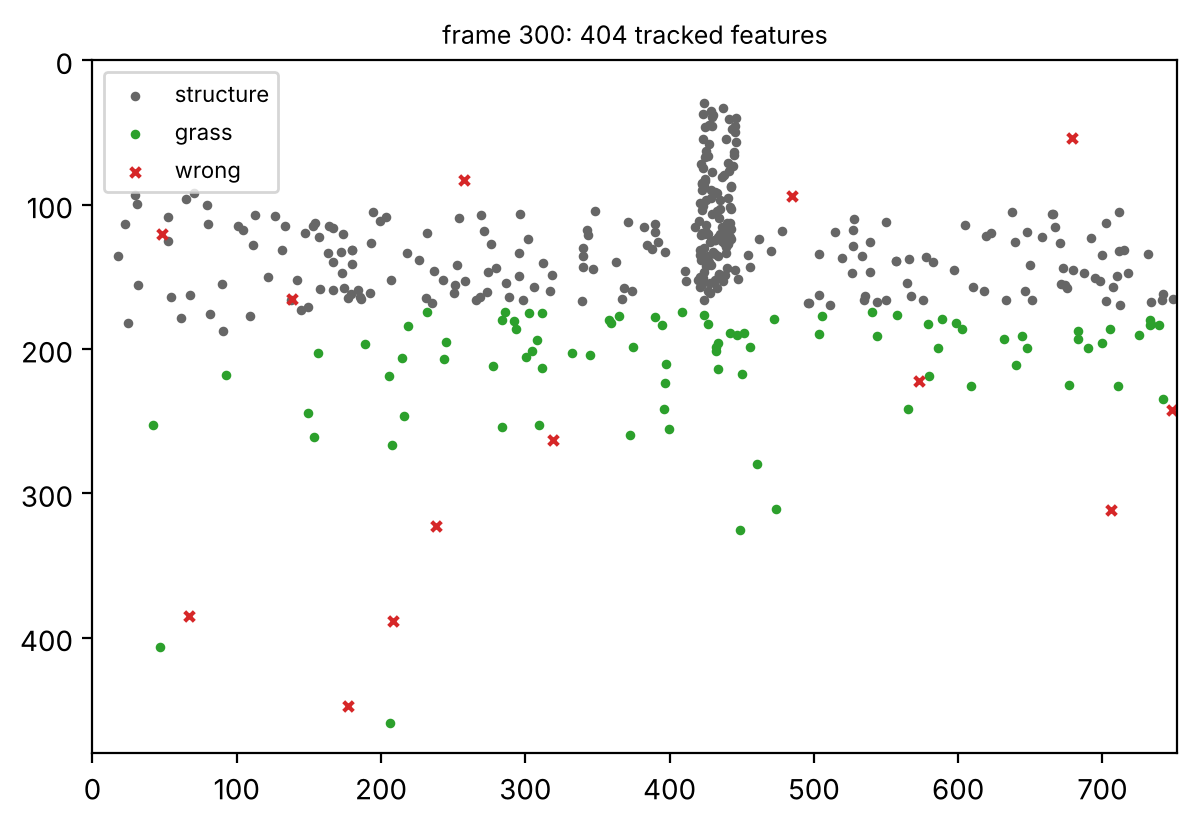

In [5]:
world = sim.garden(np.random.default_rng(0))
poses = sim.boustrophedon()
S = sim.GardenSim()
frames = S.run(world, poses, sim.camera_mount(), np.random.default_rng(1))
f = frames[300]
g = world.grass[f.landmark]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(*f.z[~g & ~f.outlier, :2].T, s=6, color="0.4", label="structure")
ax.scatter(*f.z[g & ~f.outlier, :2].T, s=6, color="tab:green", label="grass")
ax.scatter(*f.z[f.outlier, :2].T, s=12, color="tab:red", marker="x", label="wrong")
ax.set_xlim(0, 752); ax.set_ylim(480, 0); ax.set_aspect("equal"); ax.legend(fontsize=8)
ax.set_title(f"frame 300: {len(f.z)} tracked features", fontsize=9)
lifetimes = {}
for fr in frames:
    for t in fr.track_ids: lifetimes[t] = lifetimes.get(t, 0) + 1
print("median track length:", np.median(list(lifetimes.values())), "frames")

## 5. Running the stereo VO (Section 7.3)

The first 400 frames (20 m), with keyframes and frame-to-frame.

      keyframes: 50 keyframes, median inliers 220, final error 40.1 cm


 frame-to-frame: 400 keyframes, median inliers 301, final error 13.2 cm


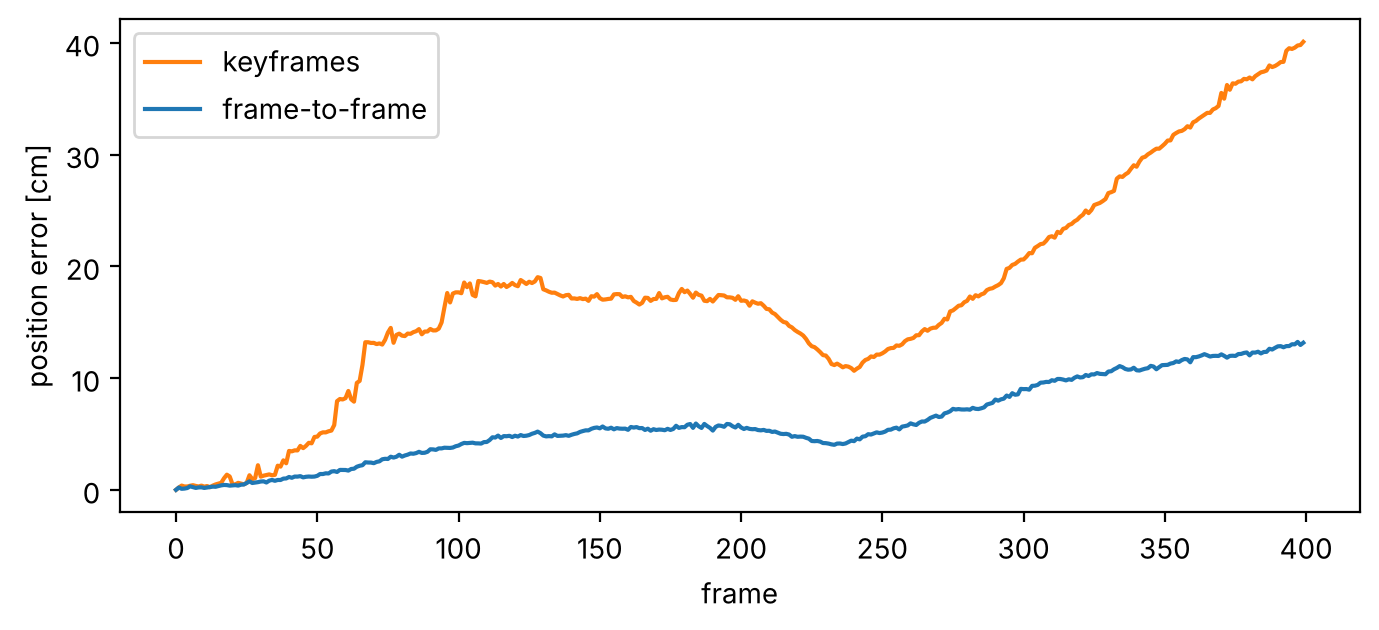

In [6]:
sub = frames[:400]
gt = np.array([fr.T_wc[:3, 3] for fr in sub])
fig, ax = plt.subplots(figsize=(8, 3.2))
for name, every, col in [("keyframes", False, "tab:orange"), ("frame-to-frame", True, "tab:blue")]:
    V = vo.StereoVO(S.stereo, SIGMA, keyframe_every_frame=every, rng=np.random.default_rng(0))
    est = V.run(sub, sub[0].T_wc)
    e = np.array([T[:3, 3] for T in est])
    ax.plot(100 * np.linalg.norm(e - gt, axis=1), color=col, label=name)
    print(f"{name:>15}: {len(V.stats.keyframes)} keyframes, median inliers {np.median(V.stats.inliers):.0f}, "
          f"final error {100 * np.linalg.norm(e[-1] - gt[-1]):.1f} cm")
ax.set_xlabel("frame"); ax.set_ylabel("position error [cm]"); ax.legend();

The keyframe version drifts *more* here. Its map is triangulated once, from a 12 cm stereo baseline, and then used
unchanged for up to a metre of motion: a point 5 m away carries a depth error of about 20 cm, and every frame
localised against it inherits that bias. Frame-to-frame odometry re-triangulates at every frame, so the depth errors
are fresh each time and partly average out. The cure is not to give up keyframes but to *refine* the keyframe map
with all the frames that see it — local bundle adjustment, Chapter 8.

## 6. The drift law (Proposition 7.5)

Simulate only the heading: each step of length $L$ adds an independent heading error of standard deviation $\sigma$.
The lateral error after $n$ steps should grow like $L\sigma\,n^{3/2}/\sqrt3$.

In [7]:
L, sig, n_steps, runs = 0.05, 1e-3, 2000, 2000
eps = rng.normal(0, sig, (runs, n_steps))
heading = np.cumsum(eps, axis=1)
lateral = np.cumsum(L * np.sin(heading), axis=1)
for n in [10, 100, 1000, 2000]:
    print(f"n = {n:5d}: Monte Carlo std {lateral[:, n - 1].std():.4f} m, "
          f"law L sigma sqrt(n(n+1)(2n+1)/6) = {L * sig * np.sqrt(n * (n + 1) * (2 * n + 1) / 6):.4f} m")

n =    10: Monte Carlo std 0.0010 m, law L sigma sqrt(n(n+1)(2n+1)/6) = 0.0010 m
n =   100: Monte Carlo std 0.0289 m, law L sigma sqrt(n(n+1)(2n+1)/6) = 0.0291 m
n =  1000: Monte Carlo std 0.9038 m, law L sigma sqrt(n(n+1)(2n+1)/6) = 0.9136 m
n =  2000: Monte Carlo std 2.5411 m, law L sigma sqrt(n(n+1)(2n+1)/6) = 2.5830 m


## 7. ATE and RPE (Section 7.4)

The same estimate scores very differently depending on the metric: ATE after alignment hides a constant offset;
RPE over short segments ignores the slow drift that ATE reveals.

In [8]:
V = vo.StereoVO(S.stereo, SIGMA, rng=np.random.default_rng(0))
est = V.run(frames, frames[0].T_wc)
gt_T = [fr.T_wc for fr in frames]
e = np.array([T[:3, 3] for T in est]); g = np.array([T[:3, 3] for T in gt_T])
print(f"position error, no alignment : RMS {np.sqrt(np.mean(np.sum((e - g) ** 2, 1))):.3f} m")
print(f"ATE after SE(3) alignment     : RMS {np.sqrt(np.mean(metrics.ate(e, g) ** 2)):.3f} m")
for d in [1.0, 5.0, 20.0]:
    te, re = metrics.rpe(est, gt_T, d)
    print(f"RPE over {d:4.0f} m: {100 * te.mean() / d:.2f} % of distance, {np.degrees(re.mean()):.2f} deg")

position error, no alignment : RMS 0.346 m
ATE after SE(3) alignment     : RMS 0.133 m
RPE over    1 m: 1.77 % of distance, 0.15 deg
RPE over    5 m: 1.16 % of distance, 0.52 deg
RPE over   20 m: 0.88 % of distance, 0.81 deg


## 8. Try it yourself

* Set `GardenSim(survive_grass=0.99)` (no wind). Does the drift change? Then set `outlier_grass=0.3`.
* Restrict keyframe map points to 8 m (`StereoVO._keyframe`). Does the keyframe VO catch up with frame-to-frame?
* Double the stereo baseline in `GardenSim` (`StereoCamera(..., 0.24)`) and compare the RPE with section 7.